In [11]:
import os
import sys
from pathlib import Path
import yaml
import numpy as np
import matplotlib.pyplot as plt
import tensorflow as tf

# Ensure notebook executes from project root
if Path.cwd().name == "notebooks":
    os.chdir("..")

project_root = Path.cwd()
if str(project_root) not in sys.path:
    sys.path.insert(0, str(project_root))

# Set reproducibility seeds
tf.random.set_seed(42)
np.random.seed(42)

print(f"Working Directory:  {project_root}")
print(f"TensorFlow Version: {tf.__version__}")

# Import our custom VisionGuard modules
from src.models.autoencoder import build_autoencoder
from src.training.train_autoencoder import train_autoencoder
from src.data.loader import create_autoencoder_datasets, create_test_dataset
from src.inference.localization import (
    compute_reconstruction_error_map,
    generate_heatmap_and_overlay,
    calculate_image_anomaly_score
)

# Load configuration
with open("configs/data.yaml", "r") as f:
    config = yaml.safe_load(f)

raw_data_dir = Path(config["dataset"]["raw_dir"])
target_categories = config["dataset"]["target_categories"]

print(f"Configuration loaded successfully for: {target_categories}")

Working Directory:  d:\Data Science\projects\VisionGuard-AI
TensorFlow Version: 2.21.0
Configuration loaded successfully for: ['metal_nut', 'screw', 'capsule']


## 1. Train Convolutional Autoencoder on Metal Nut

In [12]:
# Train Autoencoder on normal samples of metal_nut
CATEGORY = "metal_nut"
EPOCHS = 25
BATCH_SIZE = 16

results = train_autoencoder(
    category=CATEGORY,
    epochs=EPOCHS,
    batch_size=BATCH_SIZE,
    learning_rate=1e-3
)

autoencoder = results["autoencoder"]
history = results["history"]
checkpoint_path = results["checkpoint_path"]

 VisionGuard AI - Autoencoder Training: [METAL_NUT]
 Target Resolution: (256, 256)
 Batch Size:        16
 Initial LR:        0.001
 Model Checkpoint:  artifacts\models\autoencoder_metal_nut_best.keras

Dataset partitions: 187 training samples | 33 validation samples

Epoch 1/25
12/12 ━━━━━━━━━━━━━━━━━━━━ 0s 724ms/step - loss: 0.0759 - mae: 0.2432
Epoch 1: val_loss improved from None to 0.09687, saving model to artifacts\models\autoencoder_metal_nut_best.keras

Epoch 1: finished saving model to artifacts\models\autoencoder_metal_nut_best.keras
12/12 ━━━━━━━━━━━━━━━━━━━━ 15s 797ms/step - loss: 0.0759 - mae: 0.2432 - val_loss: 0.0969 - val_mae: 0.2774 - learning_rate: 0.0010
Epoch 2/25
12/12 ━━━━━━━━━━━━━━━━━━━━ 0s 646ms/step - loss: 0.0423 - mae: 0.1784
Epoch 2: val_loss improved from 0.09687 to 0.08897, saving model to artifacts\models\autoencoder_metal_nut_best.keras

Epoch 2: finished saving model to artifacts\models\autoencoder_metal_nut_best.keras
12/12 ━━━━━━━━━━━━━━━━━━━━ 8s 688m

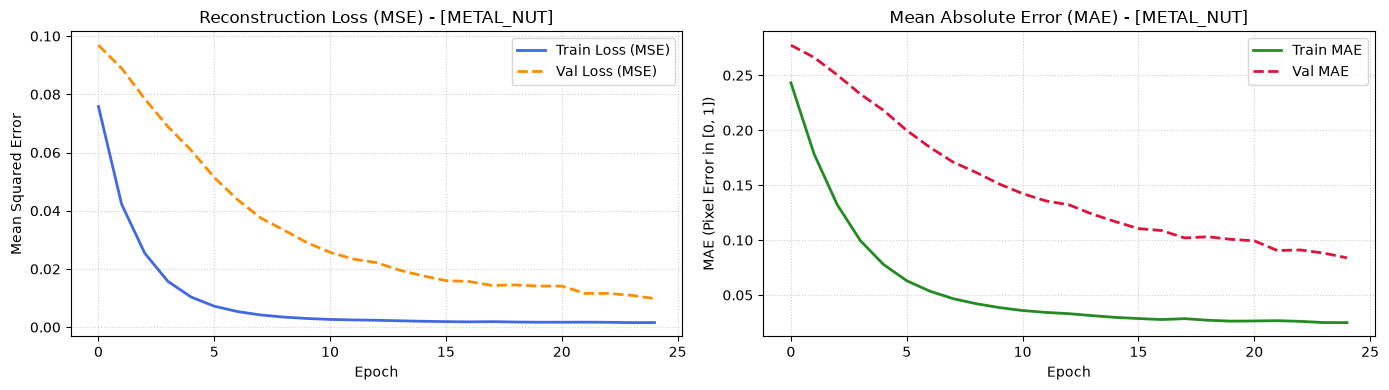

Final Best Validation Loss: 0.00984
Final Best Validation MAE:  0.08386


In [13]:
# Plot training and validation loss curves
fig, axes = plt.subplots(1, 2, figsize=(14, 4))

# 1. MSE Loss Curve
axes[0].plot(history["loss"], label="Train Loss (MSE)", color="royalblue", linewidth=2)
axes[0].plot(history["val_loss"], label="Val Loss (MSE)", color="darkorange", linewidth=2, linestyle="--")
axes[0].set_title(f"Reconstruction Loss (MSE) - [{CATEGORY.upper()}]", fontsize=12)
axes[0].set_xlabel("Epoch")
axes[0].set_ylabel("Mean Squared Error")
axes[0].legend()
axes[0].grid(True, linestyle=":", alpha=0.6)

# 2. MAE Metric Curve
axes[1].plot(history["mae"], label="Train MAE", color="forestgreen", linewidth=2)
axes[1].plot(history["val_mae"], label="Val MAE", color="crimson", linewidth=2, linestyle="--")
axes[1].set_title(f"Mean Absolute Error (MAE) - [{CATEGORY.upper()}]", fontsize=12)
axes[1].set_xlabel("Epoch")
axes[1].set_ylabel("MAE (Pixel Error in [0, 1])")
axes[1].legend()
axes[1].grid(True, linestyle=":", alpha=0.6)

plt.tight_layout()
plt.show()

print(f"Final Best Validation Loss: {min(history['val_loss']):.5f}")
print(f"Final Best Validation MAE:  {min(history['val_mae']):.5f}")

## 2. Sanity Check: Reconstructing Unseen Normal Products

Total Test Images: 115 | Normal Test Images: 22
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 312ms/step


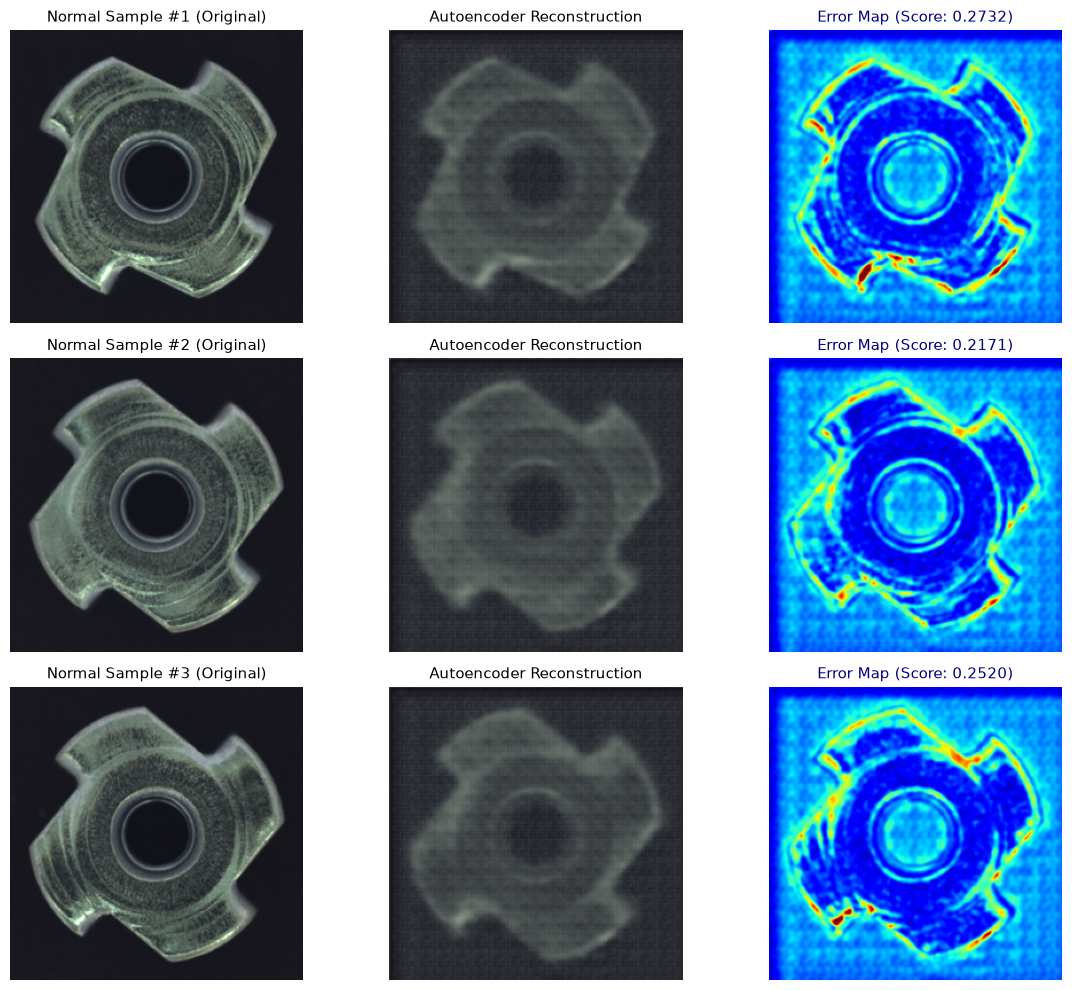

In [14]:
# 1. Load the official test dataset for metal_nut
test_ds, test_labels, n_test = create_test_dataset(CATEGORY, batch_size=32)

# Collect all test samples into memory for inspection
all_test_imgs = []
all_test_lbls = []
all_test_masks = []

for batch_imgs, batch_lbls, batch_masks in test_ds:
    all_test_imgs.append(batch_imgs.numpy())
    all_test_lbls.append(batch_lbls.numpy())
    all_test_masks.append(batch_masks.numpy())

all_test_imgs = np.concatenate(all_test_imgs, axis=0)
all_test_lbls = np.concatenate(all_test_lbls, axis=0)
all_test_masks = np.concatenate(all_test_masks, axis=0)

# Filter for normal images (label == 0)
normal_indices = np.where(all_test_lbls == 0)[0]
print(f"Total Test Images: {len(all_test_lbls)} | Normal Test Images: {len(normal_indices)}")

# Select 3 sample normal test images
sample_normal_indices = normal_indices[:3]
sample_normals = all_test_imgs[sample_normal_indices]

# Run forward pass through the trained Autoencoder
reconstructed_normals = autoencoder.predict(sample_normals)

# Plot Original vs Reconstruction vs Error Map
fig, axes = plt.subplots(3, 3, figsize=(12, 10))

for i in range(3):
    orig = sample_normals[i]
    recon = reconstructed_normals[i]
    error_map = compute_reconstruction_error_map(orig, recon)
    score = calculate_image_anomaly_score(error_map, method="top_k_mean")
    
    # 1. Original
    axes[i, 0].imshow(orig)
    axes[i, 0].set_title(f"Normal Sample #{i+1} (Original)", fontsize=11)
    axes[i, 0].axis("off")
    
    # 2. Reconstruction
    axes[i, 1].imshow(recon)
    axes[i, 1].set_title("Autoencoder Reconstruction", fontsize=11)
    axes[i, 1].axis("off")
    
    # 3. Error Map
    im = axes[i, 2].imshow(error_map, cmap="jet", vmin=0.0, vmax=0.3)
    axes[i, 2].set_title(f"Error Map (Score: {score:.4f})", fontsize=11, color="navy")
    axes[i, 2].axis("off")

plt.tight_layout()
plt.show()

## 3. Anomaly Localization: Defect Reconstruction and Inspection Overlays

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 295ms/step
==================== DEFECT INSPECTION RESULTS ====================
  • Defect: bent       | Anomaly Score: 0.2173
  • Defect: color      | Anomaly Score: 0.2133
  • Defect: flip       | Anomaly Score: 0.2897
  • Defect: scratch    | Anomaly Score: 0.2346


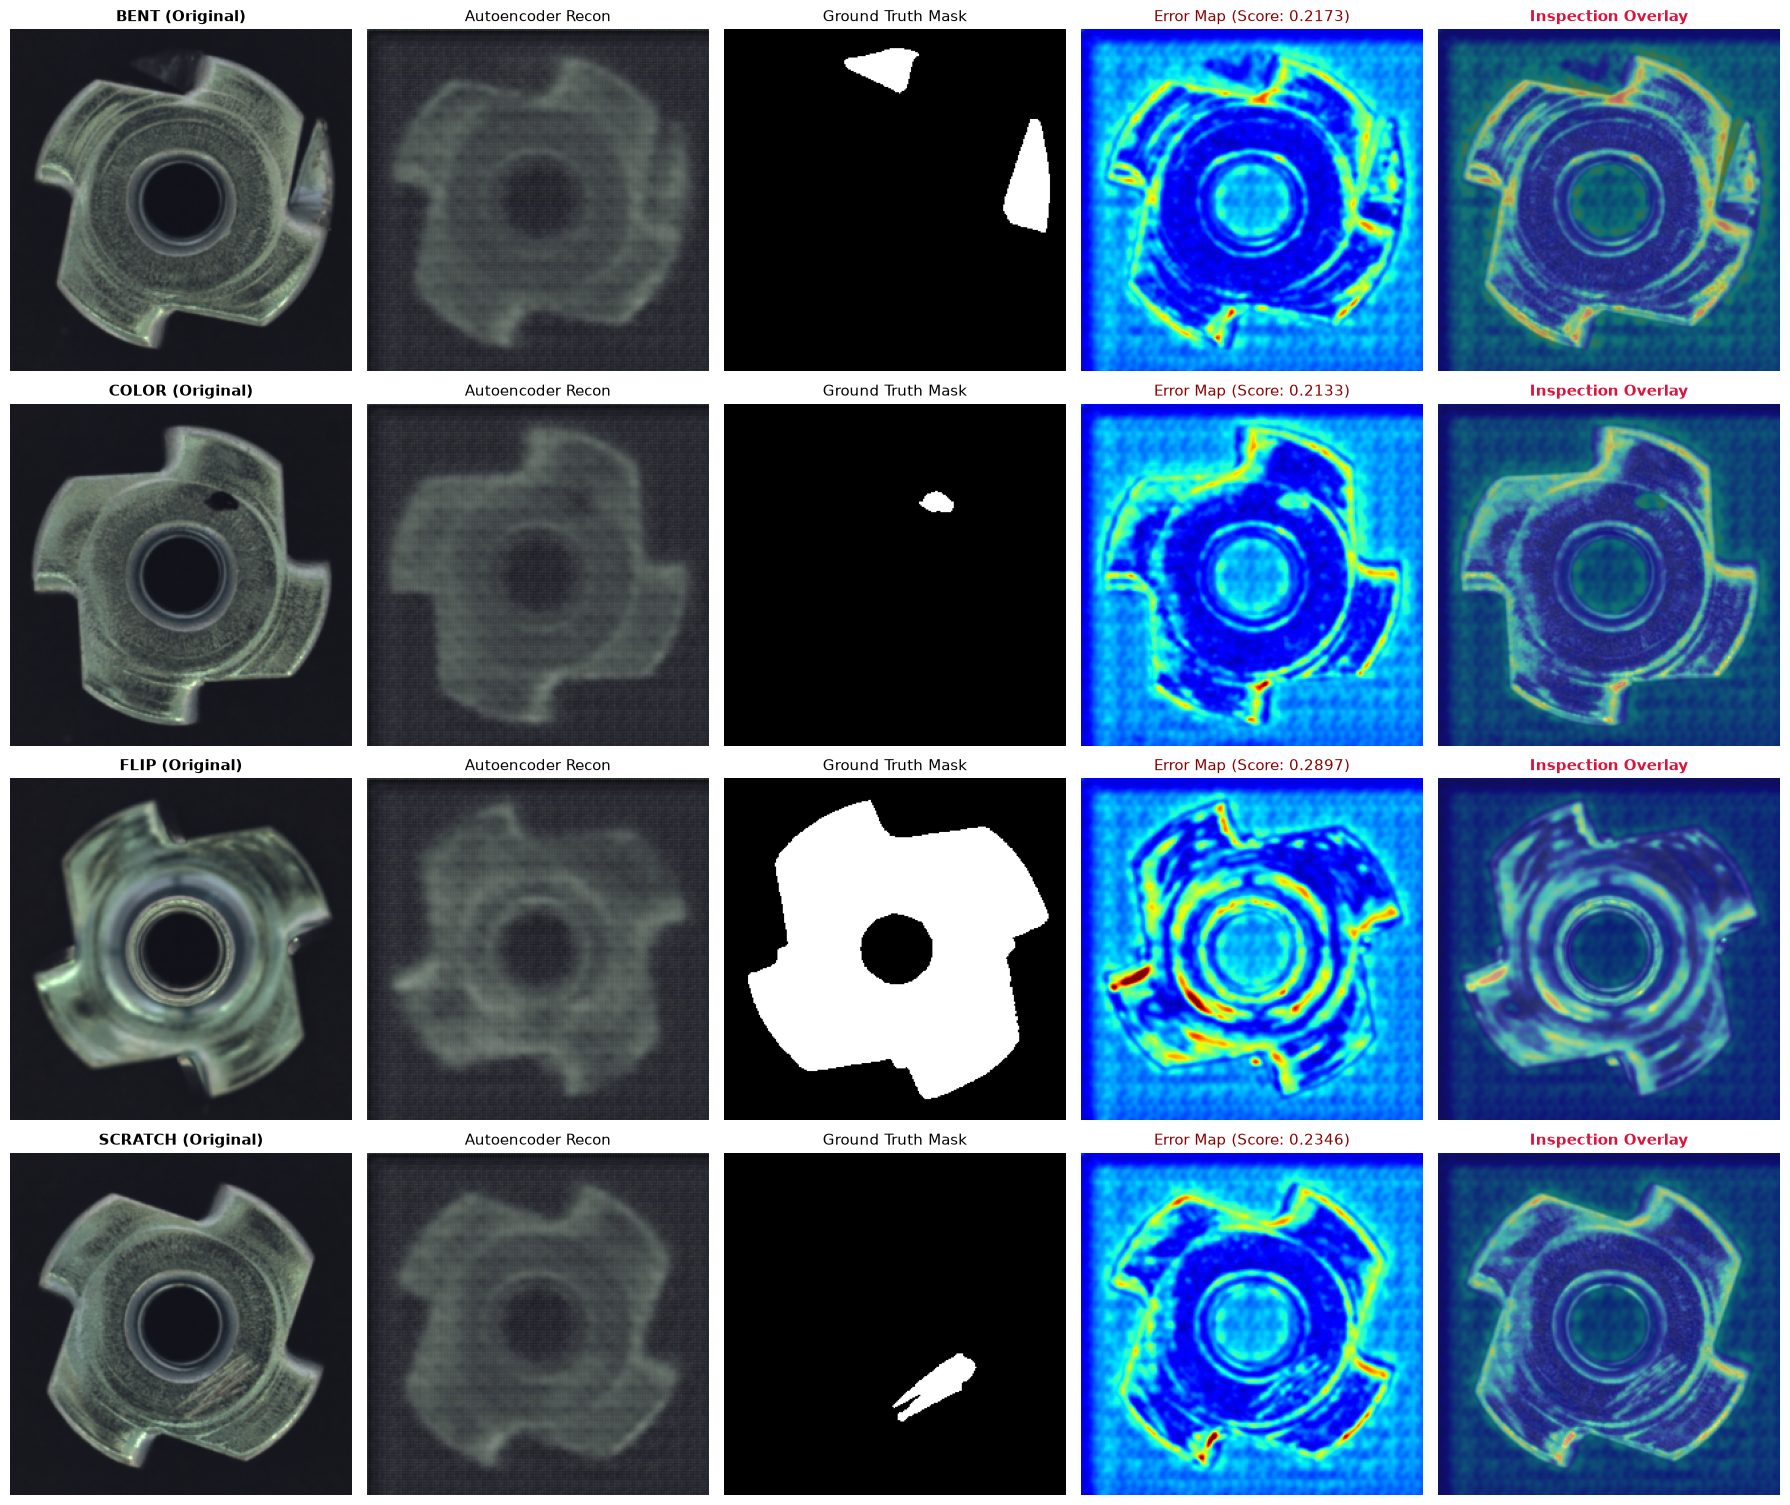

In [17]:
from src.data.loader import get_image_paths

# Collect one test sample for each defect category in metal_nut
defect_types = ["bent", "color", "flip", "scratch"]
sample_defect_indices = []

# Get all test paths to identify defect folders
test_paths, _, _ = get_image_paths(raw_data_dir / CATEGORY, split="test")

for d_type in defect_types:
    # Find the index of the first image matching this defect type
    idx = next(i for i, path in enumerate(test_paths) if f"test\\{d_type}\\" in path or f"test/{d_type}/" in path)
    sample_defect_indices.append(idx)

# Extract images and ground-truth masks
defect_imgs = all_test_imgs[sample_defect_indices]
defect_masks = all_test_masks[sample_defect_indices]

# Run forward pass through the trained Autoencoder
reconstructed_defects = autoencoder.predict(defect_imgs)

# Create 5-column inspection figure: [Original, Recon, GroundTruth, ErrorMap, Overlay]
fig, axes = plt.subplots(len(defect_types), 5, figsize=(18, 3.8 * len(defect_types)))

print("==================== DEFECT INSPECTION RESULTS ====================")

for i, d_type in enumerate(defect_types):
    orig = defect_imgs[i]
    recon = reconstructed_defects[i]
    gt_mask = defect_masks[i].squeeze()
    
    # Compute error map and thermal overlay
    error_map = compute_reconstruction_error_map(orig, recon)
    heatmap, overlay = generate_heatmap_and_overlay(orig, error_map, alpha=0.6)
    score = calculate_image_anomaly_score(error_map, method="top_k_mean")
    
    print(f"  • Defect: {d_type:<10} | Anomaly Score: {score:.4f}")
    
    # Col 1: Original
    axes[i, 0].imshow(orig)
    axes[i, 0].set_title(f"{d_type.upper()} (Original)", fontsize=11, fontweight="bold")
    axes[i, 0].axis("off")
    
    # Col 2: Reconstruction
    axes[i, 1].imshow(recon)
    axes[i, 1].set_title("Autoencoder Recon", fontsize=11)
    axes[i, 1].axis("off")
    
    # Col 3: Ground Truth Mask
    axes[i, 2].imshow(gt_mask, cmap="gray")
    axes[i, 2].set_title("Ground Truth Mask", fontsize=11)
    axes[i, 2].axis("off")
    
    # Col 4: Error Map
    axes[i, 3].imshow(error_map, cmap="jet", vmin=0.0, vmax=0.3)
    axes[i, 3].set_title(f"Error Map (Score: {score:.4f})", fontsize=11, color="darkred")
    axes[i, 3].axis("off")
    
    # Col 5: Overlay
    axes[i, 4].imshow(overlay)
    axes[i, 4].set_title("Inspection Overlay", fontsize=11, fontweight="bold", color="crimson")
    axes[i, 4].axis("off")

plt.tight_layout()
plt.show()

## 4. Quantitative Evaluation: Full Test Set Score Distribution & AUROC

Scoring all 115 test images through the pipeline...
4/4 ━━━━━━━━━━━━━━━━━━━━ 1s 280ms/step
==================== FULL TEST SET SUMMARY ====================
  • Normal Images Count: 22 | Mean Score: 0.2647 (±0.0306)
  • Defect Images Count: 93 | Mean Score: 0.2419 (±0.0246)
  • Baseline Conv Autoencoder AUROC: 25.61%



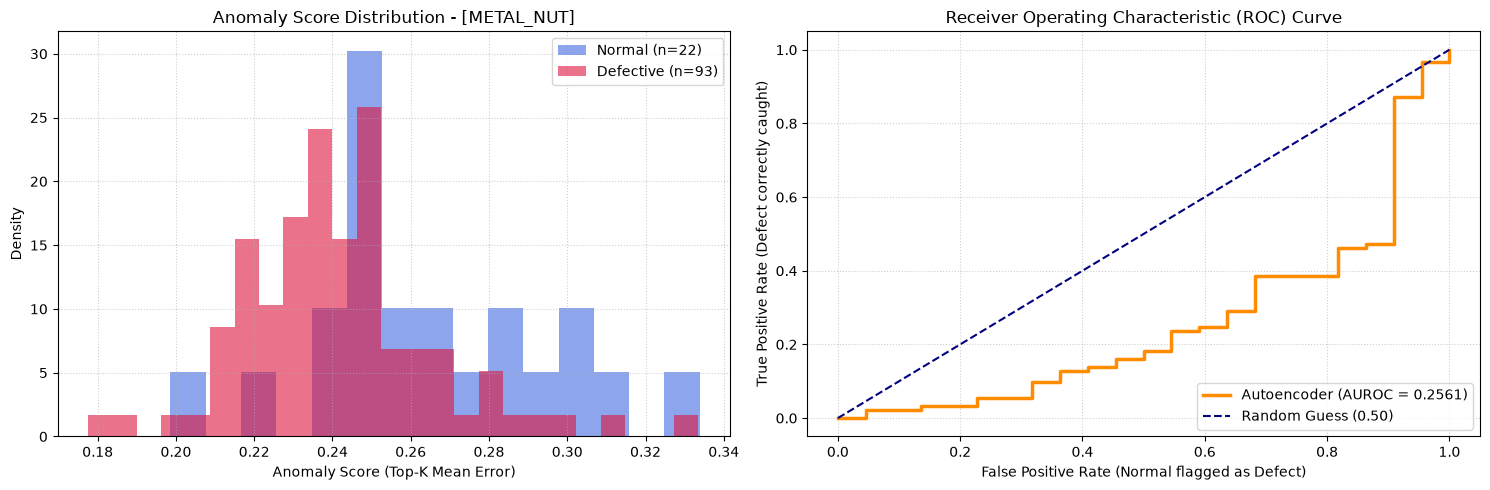

In [18]:
from sklearn.metrics import roc_auc_score, roc_curve

print(f"Scoring all {len(all_test_imgs)} test images through the pipeline...")

# 1. Run forward pass on all test images
all_reconstructions = autoencoder.predict(all_test_imgs, batch_size=32)

# 2. Compute anomaly score for every single test image
all_anomaly_scores = []
for i in range(len(all_test_imgs)):
    e_map = compute_reconstruction_error_map(all_test_imgs[i], all_reconstructions[i])
    s = calculate_image_anomaly_score(e_map, method="top_k_mean")
    all_anomaly_scores.append(s)

all_anomaly_scores = np.array(all_anomaly_scores)

# 3. Separate scores for normal vs defective products
normal_scores = all_anomaly_scores[all_test_lbls == 0]
defect_scores = all_anomaly_scores[all_test_lbls == 1]

# 4. Calculate Image-Level AUROC
image_auroc = roc_auc_score(all_test_lbls, all_anomaly_scores)
fpr, tpr, thresholds = roc_curve(all_test_lbls, all_anomaly_scores)

print("==================== FULL TEST SET SUMMARY ====================")
print(f"  • Normal Images Count: {len(normal_scores)} | Mean Score: {normal_scores.mean():.4f} (±{normal_scores.std():.4f})")
print(f"  • Defect Images Count: {len(defect_scores)} | Mean Score: {defect_scores.mean():.4f} (±{defect_scores.std():.4f})")
print(f"  • Baseline Conv Autoencoder AUROC: {image_auroc * 100:.2f}%\n")

# 5. Plot Score Distribution & ROC Curve
fig, axes = plt.subplots(1, 2, figsize=(15, 5))

# Plot 1: Histogram / Distribution
axes[0].hist(normal_scores, bins=15, alpha=0.6, color="royalblue", label=f"Normal (n={len(normal_scores)})", density=True)
axes[0].hist(defect_scores, bins=25, alpha=0.6, color="crimson", label=f"Defective (n={len(defect_scores)})", density=True)
axes[0].set_title(f"Anomaly Score Distribution - [{CATEGORY.upper()}]", fontsize=12)
axes[0].set_xlabel("Anomaly Score (Top-K Mean Error)")
axes[0].set_ylabel("Density")
axes[0].legend()
axes[0].grid(True, linestyle=":", alpha=0.6)

# Plot 2: ROC Curve
axes[1].plot(fpr, tpr, color="darkorange", linewidth=2.5, label=f"Autoencoder (AUROC = {image_auroc:.4f})")
axes[1].plot([0, 1], [0, 1], color="navy", linestyle="--", linewidth=1.5, label="Random Guess (0.50)")
axes[1].set_title(f"Receiver Operating Characteristic (ROC) Curve", fontsize=12)
axes[1].set_xlabel("False Positive Rate (Normal flagged as Defect)")
axes[1].set_ylabel("True Positive Rate (Defect correctly caught)")
axes[1].legend(loc="lower right")
axes[1].grid(True, linestyle=":", alpha=0.6)

plt.tight_layout()
plt.show()

## 5. Diagnostic Error Analysis: Why Vanilla Pixel-MSE Autoencoders Fail on Rigid Corners

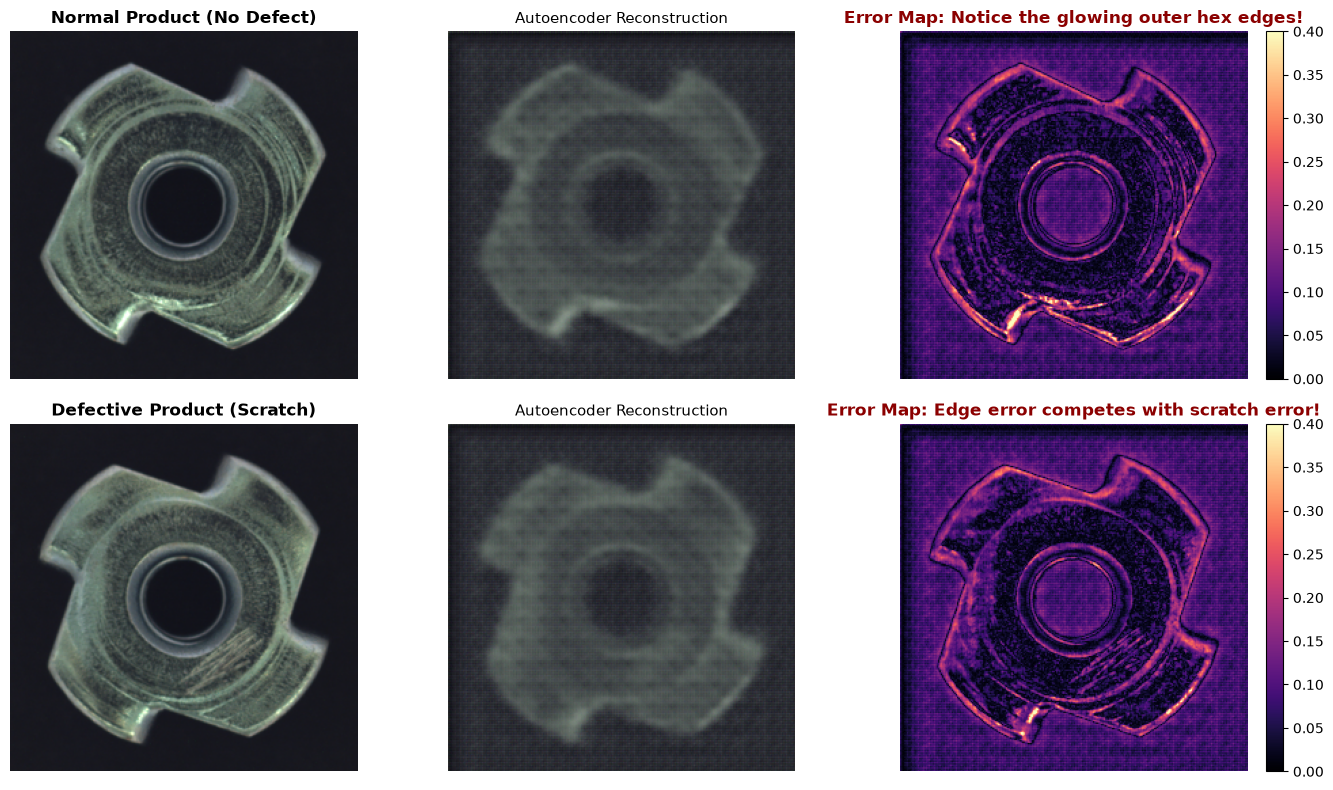


--- ARCHITECTURAL DIAGNOSIS ---
1. Root Cause: High-frequency hexagonal corners suffer from slight spatial reconstruction blur.
2. The high intensity gradient at object edges creates larger absolute error than subtle surface scratches.
3. Next Step (Milestone 03 & 04): Implement Structural Similarity (SSIM) loss, edge-masking, and PatchCore feature embeddings.


In [19]:
# Select 1 Normal sample and 1 Scratch sample
sample_normal_img = all_test_imgs[normal_indices[0]]
sample_scratch_img = defect_imgs[defect_types.index("scratch")]

# Get reconstructions
sample_normal_recon = autoencoder.predict(np.expand_dims(sample_normal_img, 0), verbose=0)[0]
sample_scratch_recon = autoencoder.predict(np.expand_dims(sample_scratch_img, 0), verbose=0)[0]

# Compute raw error maps (WITHOUT top-k clipping)
normal_err_raw = np.mean(np.abs(sample_normal_img - sample_normal_recon), axis=-1)
scratch_err_raw = np.mean(np.abs(sample_scratch_img - sample_scratch_recon), axis=-1)

# Visualize where the errors actually live
fig, axes = plt.subplots(2, 3, figsize=(14, 8))

# Row 1: Normal Sample
axes[0, 0].imshow(sample_normal_img)
axes[0, 0].set_title("Normal Product (No Defect)", fontweight="bold")
axes[0, 0].axis("off")

axes[0, 1].imshow(sample_normal_recon)
axes[0, 1].set_title("Autoencoder Reconstruction", fontsize=11)
axes[0, 1].axis("off")

im1 = axes[0, 2].imshow(normal_err_raw, cmap="magma", vmin=0.0, vmax=0.4)
axes[0, 2].set_title("Error Map: Notice the glowing outer hex edges!", color="darkred", fontweight="bold")
axes[0, 2].axis("off")
fig.colorbar(im1, ax=axes[0, 2], fraction=0.046, pad=0.04)

# Row 2: Scratch Sample
axes[1, 0].imshow(sample_scratch_img)
axes[1, 0].set_title("Defective Product (Scratch)", fontweight="bold")
axes[1, 0].axis("off")

axes[1, 1].imshow(sample_scratch_recon)
axes[1, 1].set_title("Autoencoder Reconstruction", fontsize=11)
axes[1, 1].axis("off")

im2 = axes[1, 2].imshow(scratch_err_raw, cmap="magma", vmin=0.0, vmax=0.4)
axes[1, 2].set_title("Error Map: Edge error competes with scratch error!", color="darkred", fontweight="bold")
axes[1, 2].axis("off")
fig.colorbar(im2, ax=axes[1, 2], fraction=0.046, pad=0.04)

plt.tight_layout()
plt.show()

print("\n--- ARCHITECTURAL DIAGNOSIS ---")
print("1. Root Cause: High-frequency hexagonal corners suffer from slight spatial reconstruction blur.")
print("2. The high intensity gradient at object edges creates larger absolute error than subtle surface scratches.")
print("3. Next Step (Milestone 03 & 04): Implement Structural Similarity (SSIM) loss, edge-masking, and PatchCore feature embeddings.")